#### First Agent
stop running the tool loop by hand, let the model decide what to do and how many times. Read the trace, watch it decide step by step, cap the loop, and give the agent a memory.

In [1]:
import time

from dotenv import load_dotenv
from langchain_openrouter import ChatOpenRouter
from langchain.tools import tool
from langchain.messages import HumanMessage

load_dotenv()

model = ChatOpenRouter(model="nvidia/nemotron-3.5-lightning:free", temperature=0)

#### 1. Rebuild previous two tools

In [3]:
import ollama

@tool
def multiply(a: float, b: float) -> float:
    """Multiply two numbers together and return the exact result."""
    return a * b


@tool
def web_search(query: str) -> str:
    """Search the live web and return the top results. Use for questions about current events, prices or rates."""
    results = ollama.web_search(query, max_results=3).results
    parts = []
    for r in results:
        parts.append(r.title + " (" + r.url + ")\n" + r.content[:300])
    return "\n\n".join(parts)

in previous file i did the middle part yourself: read tool_calls, run the function, wrap it in a ToolMessage, call the model again.

That loop never changes. Today something else runs it.

#### 2. Build an agent with create_agent

In [4]:
from langchain.agents import create_agent

agent = create_agent(
    model = model,
    tools = [multiply, web_search],
    system_prompt="""You are a helpful assistant.
Always use a tool for any calculation. Never do arithmetic yourself.
Use web_search for live information such as exchange rates."""
)

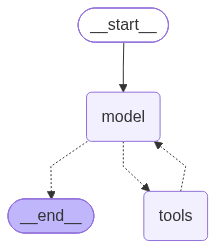

In [5]:
agent

A model, the tools it may use, and one instruction about when to use them.

#### 3. Ask it something that needs two steps

In [6]:
question = "I am buying 12 items at 250 dollars each. How many rupees is that at today's exchange rate?"

result = agent.invoke({"messages": [HumanMessage(question)]})

result

{'messages': [HumanMessage(content="I am buying 12 items at 250 dollars each. How many rupees is that at today's exchange rate?", additional_kwargs={}, response_metadata={}, id='c8bdaa59-bc3a-4021-8b7a-6e5cb6767326'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to calculate total dollars: 12 * 250 = 3000 dollars. Then convert to rupees at today\'s exchange rate. Use web_search to get today\'s USD to INR exchange rate. Then multiply 3000 by that rate. Use multiply tool.\n\nFirst, search "USD to INR exchange rate today".', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'We need to calculate total dollars: 12 * 250 = 3000 dollars. Then convert to rupees at today\'s exchange rate. Use web_search to get today\'s USD to INR exchange rate. Then multiply 3000 by that rate. Use multiply tool.\n\nFirst, search "USD to INR exchange rate today".'}]}, response_metadata={'model_name': 'nvidia/nemotron-3.5-lightning:free', 'id': 

#### 4. Read the trace: every step is a message
Every step is a message.

In [7]:
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

I am buying 12 items at 250 dollars each. How many rupees is that at today's exchange rate?
================================== Ai Message ==================================
Tool Calls:
  web_search (call-3340e26b-4a36-4568-87a1-cb6ebfdac709)
 Call ID: call-3340e26b-4a36-4568-87a1-cb6ebfdac709
  Args:
    query: USD to INR exchange rate today
================================= Tool Message =================================
Name: web_search

USDINR | Latest quote: 94.947862 (+0.01%) | As of 2026-10-24T14:25:01Z (https://exa.ai/library/markets/forex/USDINR)
# USDINR

The latest quote for USDINR is 94.947862 as of 2026-10-24T14:25:01Z, up +0.007862 (+0.01%) from the previous close.

## Trading Session

- Trading Day: October 24, 2026
- Close: 94.947862

## Previous Close

- Close: 94.940000

1 USD = ₹94.9948 | USD to INR Live Rate · 24 Oct 2026 | Capera (https://capera.co/rates/fx/USD-INR)
1 USD = ₹94.9948 | U

Top to bottom:

1. Human asked the question.
2. Ai decided to call a tool and filled in the arguments.
3. Tool returned the real number, computed by Python.
4. Steps 2 and 3 repeat as often as the model decides.
5. Ai wrote the final sentence.

Exactly the loop you wrote by hand yesterday. The only new thing is who decides when to stop.

In a real product this list is the record that explains why your assistant said what it said. Never throw it away.

#### 5. Watch each decision with .stream()
.stream() shows each step as it completes, instead of waiting for the final answer.

In [8]:
result['messages'][-1].text

'The total cost in U.S. dollars is  \n\n\\(12 \\times 250 = \\$3{,}000\\).\n\nUsing today’s approximate exchange rate of **1\u202fUSD\u202f≈\u202f₹94.90** (mid‑market rate from the live search), the conversion is  \n\n\\(3{,}000 \\times 94.90 = \\mathbf{₹284{,}700}\\).\n\nSo, 12 items at $250 each would be about **₹284,700** at today’s rate. (The exact amount will vary slightly depending on the precise exchange rate at the moment of transaction.)'

In [9]:
# time.sleep(6)

for step in agent.stream(
    {"messages": [HumanMessage("What is 8 times 4 dollars in rupees?")]},
    stream_mode="updates",
):
    for node, update in step.items():
        # print('node: ', node)
        # print('\n\nupdate: ', update)
        last = update["messages"][-1]
        print(node + ": " + (last.text or str(last.tool_calls))[:90])

model: [{'name': 'web_search', 'args': {'query': 'USD to INR exchange rate'}, 'id': 'call-6bf56f7
tools: USDINR | Latest quote: 94.946688 (+0.01%) | As of 2026-10-24T14:35:58Z (https://exa.ai/lib
model: [{'name': 'multiply', 'args': {'a': 32, 'b': 94.9948}, 'id': 'call-76fd08b9-8d4c-4bc0-94c0
tools: 3039.8336
model: 8 × $4 = $32.  
Using the current mid‑market exchange rate of 1 USD ≈ ₹94.9948 (as of 24 O


stream_mode="updates" gives one item per completed step, how you'd build a "thinking..." display.

Also the best debugging tool here: a strange answer's reason is almost always visible in the middle steps, not the last one.

#### 6. An agent costs more than a chain
An agent calls the model to decide, then again to answer. A chain makes one call and does exactly what you planned.

In [10]:

model.invoke("Say hello in one word.")

AIMessage(content='Hello', additional_kwargs={'reasoning_content': 'Here\'s a thinking process:\n\n1.  **Analyze User Input:** The user says "Say hello in one word."\n2.  **Identify Core Request:** The user wants a greeting, specifically in one word.\n3.  **Determine Response:** The most direct one-word hello is "Hello" itself, or alternatives like "Hi", "Hey", "Hola", etc. Since the request is "Say hello in one word", the literal answer is "Hello". It fits the constraint (one word).\n4.  **Formulate Response:** Just output "Hello". Or maybe "Hi" if they want a common alternative, but "Hello" is safest and most literal.\n5.  **Check Constraints:** One word only. "Hello" is one word.\n6.  **Output:** Hello\n\nWait, let me just output exactly that. The prompt is straightforward. I\'ll respond with "Hello".✅', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'Here\'s a thinking process:\n\n1.  **Analyze User Input:** The user says "Say hello in one

In [11]:
# time.sleep(6)

simple = agent.invoke({"messages": [HumanMessage("Say hello in one word.")]})

simple

{'messages': [HumanMessage(content='Say hello in one word.', additional_kwargs={}, response_metadata={}, id='84c189b6-fd51-4e53-8267-3b61724e69e1'),
  AIMessage(content='Hello', additional_kwargs={'reasoning_content': 'The user says: "Say hello in one word." That\'s a simple request: output a single word that means hello. Possibly "Hello". But they want one word. So answer "Hello". No tool needed. But the instruction says "Always use a tool for any calculation." This is not a calculation. It\'s just a phrase. So we can just answer. Possibly we could use web_search? Not needed. So just answer.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'The user says: "Say hello in one word." That\'s a simple request: output a single word that means hello. Possibly "Hello". But they want one word. So answer "Hello". No tool needed. But the instruction says "Always use a tool for any calculation." This is not a calculation. It\'s just a phrase. So we can j

Even a trivial question costs at least two messages through an agent.

Every message in that trace carries its own usage_metadata, and an agent produces more of them than a chain does.

   Use a chain when you already know the steps. Use an agent when the next step depends on what came back.

An agent buys decisions, and decisions cost round trips.

In [13]:
from langchain.agents.middleware import ModelCallLimitMiddleware

limited = create_agent(
    model=model,
    tools=[multiply, web_search],
    system_prompt="Always use a tool for any calculation.",
    middleware=[ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")]
)

In [14]:

question

"I am buying 12 items at 250 dollars each. How many rupees is that at today's exchange rate?"

In [15]:
# time.sleep(6)

capped = limited.invoke({"messages": [HumanMessage(question)]})

capped

{'messages': [HumanMessage(content="I am buying 12 items at 250 dollars each. How many rupees is that at today's exchange rate?", additional_kwargs={}, response_metadata={}, id='733f801e-3e6d-47c3-98eb-d7665c23f812'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to calculate total dollars: 12 * 250 = 3000 dollars. Then convert to rupees at today\'s exchange rate. Need to get today\'s exchange rate USD to INR. Use web_search to find current rate. Then multiply. Let\'s search "USD to INR exchange rate today".', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'We need to calculate total dollars: 12 * 250 = 3000 dollars. Then convert to rupees at today\'s exchange rate. Need to get today\'s exchange rate USD to INR. Use web_search to find current rate. Then multiply. Let\'s search "USD to INR exchange rate today".'}]}, response_metadata={'model_name': 'nvidia/nemotron-3.5-lightning:free', 'id': 'gen-1792853522-1zOrzfdOhp

In [16]:
# time.sleep(6)

capped = limited.invoke({"messages": [HumanMessage("what is weather in mumbai")]})

capped

{'messages': [HumanMessage(content='what is weather in mumbai', additional_kwargs={}, response_metadata={}, id='73147a64-2fba-4d52-a389-dde993202c44'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks "what is weather in mumbai". Need current weather. Use web_search tool.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'The user asks "what is weather in mumbai". Need current weather. Use web_search tool.'}]}, response_metadata={'model_name': 'nvidia/nemotron-3.5-lightning:free', 'id': 'gen-1792853557-lhexNCF0Z5HvtlGgLMuf', 'created': 1792853557, 'object': 'chat.completion', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.0, 'cost_details': {'upstream_inference_completions_cost': 0.0, 'upstream_inference_prompt_cost': 0.0, 'upstream_inference_cost': 0.0}}, id='lc_run--01a16e66-3b45-75d6-a5d0-90e42b20da9b-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'current we

run_limit caps calls per question. exit_behavior="end" stops cleanly; "error" raises instead, useful in a batch job where a silent partial answer is worse than a failure.

Put a limit on anything unattended. An agent looping against a paid API is how you discover your billing alerts don't work.

#### 8. Add Day 6's checkpointer to the agent
checkpointer works here unchanged, this is where the two halves of the course meet.

In [18]:
from langgraph.checkpoint.memory import InMemorySaver

assistant = create_agent(
    model=model,
    tools=[multiply, web_search],
    system_prompt="You are a helpful shopping assistant. Use tools for arithmetic and web_search for exchange rates.",
    checkpointer=InMemorySaver(),
)

cfg = {"configurable": {"thread_id": "shopper"}}

In [19]:

# time.sleep(6)

response = assistant.invoke(
    {"messages": [HumanMessage("How many rupees is 40 dollars?")]},
    config=cfg,
)

response

{'messages': [HumanMessage(content='How many rupees is 40 dollars?', additional_kwargs={}, response_metadata={}, id='13541ab3-d698-4667-b337-5e37de95d00d'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to convert 40 dollars to rupees. Likely need current exchange rate. Use web_search for "40 USD to INR" or "dollar to rupee exchange rate". Then multiply. Let\'s search.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'We need to convert 40 dollars to rupees. Likely need current exchange rate. Use web_search for "40 USD to INR" or "dollar to rupee exchange rate". Then multiply. Let\'s search.'}]}, response_metadata={'model_name': 'nvidia/nemotron-3.5-lightning:free', 'id': 'gen-1792853665-HDLWcjoSrJnGNlfjZ1V1', 'created': 1792853665, 'object': 'chat.completion', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.0, 'cost_details': {'upstream_inference_completions_cost': 0.0, 'up

In [20]:
# time.sleep(6)

response = assistant.invoke(
    {"messages": [HumanMessage("And if I buy three of them?")]},
    config=cfg,
)

response

{'messages': [HumanMessage(content='How many rupees is 40 dollars?', additional_kwargs={}, response_metadata={}, id='13541ab3-d698-4667-b337-5e37de95d00d'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to convert 40 dollars to rupees. Likely need current exchange rate. Use web_search for "40 USD to INR" or "dollar to rupee exchange rate". Then multiply. Let\'s search.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'We need to convert 40 dollars to rupees. Likely need current exchange rate. Use web_search for "40 USD to INR" or "dollar to rupee exchange rate". Then multiply. Let\'s search.'}]}, response_metadata={'model_name': 'nvidia/nemotron-3.5-lightning:free', 'id': 'gen-1792853665-HDLWcjoSrJnGNlfjZ1V1', 'created': 1792853665, 'object': 'chat.completion', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.0, 'cost_details': {'upstream_inference_completions_cost': 0.0, 'up

"Three of them" only means something if the previous turn is still there, the checkpointer kept the whole trace, tool calls included.

An agent with memory and tools is, structurally, what people mean by "an AI assistant". You've now built one.